<a href="https://colab.research.google.com/github/krishhh-na/Tareas-FIS1344-1/blob/main/Tarea_7_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np                              #importamos bibliotecas
import matplotlib.pyplot as plt
from scipy.special import erf

def f(x):                                       #definimos la función
  return np.exp(-x**2 /2) / np.sqrt(2*np.pi)

a = 0                                           #definimos variables
b = 3

Integral_exacta = 0.5 * erf (3/np.sqrt(2))       #usamos la función error
print("Valor integral exacta:", Integral_exacta)

Valor integral exacta: 0.4986501019683699


In [2]:
class MaxIterations(Exception):
    pass

def adaptive(f, a, b, tol, N=100_000):   #la función recibe 5 argumentos (función, limite inferior y superior, tolerancia, máximo de subdivisiones)

    # Variables iniciales
    approx = 0
    i = 0
    toli = [10*tol]
    ai = [a]
    hi = [(b - a)/2]
    fai = [f(a)]
    fbi = [f(b)]
    fci = [f(a + hi[i])]
    S0i = [hi[i]*(fai[i] + 4*fci[i] + fbi[i])/3]
    Li = [1]

    while i >= 0:

        fd = f(ai[i] + hi[i]/2)
        fe = f(ai[i] + 3*hi[i]/2)

        S1 = hi[i]*(fai[i] + 4*fd + fci[i])/6
        S2 = hi[i]*(fci[i] + 4*fe + fbi[i])/6

        ai_prec = ai[i]
        hi_prec = hi[i]
        fai_prec = fai[i]
        fbi_prec = fbi[i]
        fci_prec = fci[i]
        toli_prec = toli[i]
        S0i_prec = S0i[i]
        Li_prec = Li[i]

        i -= 1

        if abs(S1 + S2 - S0i_prec) < toli_prec:
            approx += S1 + S2

        else:
            if Li_prec >= N:
                raise MaxIterations(
                    "Alcanzado máximo número de iteraciones."
                )

            # Intervalo derecho
            i += 1

            if i >= len(ai):
                ai.append(ai_prec + hi_prec)
                fai.append(fci_prec)
                fci.append(fe)
                fbi.append(fbi_prec)
                hi.append(hi_prec/2)
                toli.append(toli_prec/2)
                S0i.append(S2)
                Li.append(Li_prec + 1)

            else:
                ai[i] = ai_prec + hi_prec
                fai[i] = fci_prec
                fci[i] = fe
                fbi[i] = fbi_prec
                hi[i] = hi_prec/2
                toli[i] = toli_prec/2
                S0i[i] = S2
                Li[i] = Li_prec + 1

            # Intervalo izquierdo
            i += 1

            if i >= len(ai):
                ai.append(ai_prec)
                fai.append(fai_prec)
                fci.append(fd)
                fbi.append(fci_prec)
                hi.append(hi[i-1])
                toli.append(toli[i-1])
                S0i.append(S1)
                Li.append(Li[i-1])

            else:
                ai[i] = ai_prec
                fai[i] = fai_prec
                fci[i] = fd
                fbi[i] = fci_prec
                hi[i] = hi[i-1]
                toli[i] = toli[i-1]
                S0i[i] = S1
                Li[i] = Li[i-1]

    return approx


In [3]:
tolerancias = [1e-2, 1e-3, 1e-4, 1e-5,     #definimos varias tolerancias
               1e-6, 1e-7, 1e-8, 1e-9]

aproximaciones = []
errores = []

for tol in tolerancias:               #calculamos la integral para cada tolerancia

    I_aprox = adaptive(f, a, b, tol)

    error = abs(I_aprox - Integral_exacta)   #calculamos error absoluto

    aproximaciones.append(I_aprox)
    errores.append(error)

    print(f"Tolerancia: {tol:.0e} | "
          f"Integral: {I_aprox:.12f} | "
          f"Error: {error:.6e}")


Tolerancia: 1e-02 | Integral: 0.498479414027 | Error: 1.706879e-04
Tolerancia: 1e-03 | Integral: 0.498641534550 | Error: 8.567418e-06
Tolerancia: 1e-04 | Integral: 0.498641534550 | Error: 8.567418e-06
Tolerancia: 1e-05 | Integral: 0.498665376500 | Error: 1.527453e-05
Tolerancia: 1e-06 | Integral: 0.498650100451 | Error: 1.517345e-09
Tolerancia: 1e-07 | Integral: 0.498650089790 | Error: 1.217854e-08
Tolerancia: 1e-08 | Integral: 0.498650101853 | Error: 1.155124e-10
Tolerancia: 1e-09 | Integral: 0.498650102006 | Error: 3.768963e-11


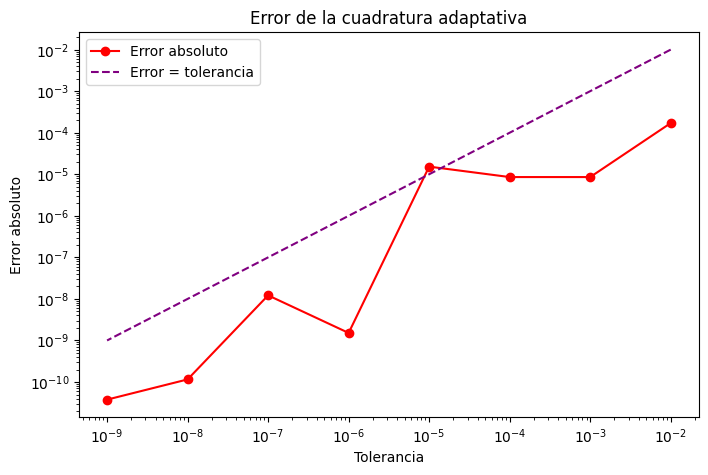

In [9]:

plt.figure(figsize=(8, 5))

plt.loglog(tolerancias, errores, 'o-', color= 'red', label='Error absoluto')      #usamos escalas logaritmicas

plt.loglog(tolerancias, tolerancias, '--', color= 'purple', label='Error = tolerancia')

plt.xlabel('Tolerancia')
plt.ylabel('Error absoluto')
plt.title('Error de la cuadratura adaptativa')
plt.legend()
plt.show()


Se esperaba que al disminuir la tolerancia se tendria un menor error, ya que el método de cuadratura adaptativa busca mejorar la presición de este. Al observar el gráfico podemos ver que las tolerancias pequeñas implican un error más pequeño.

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.
